### Aula do dia 15/10/2026

Análise exploratória de dados

In [26]:
import pandas as pd
import math

df = pd.read_csv('vendas.csv', parse_dates=['data_venda'])

In [27]:
print('--- Valores Duplicados ---')
display(df[df.duplicated(keep=False)]) 

# Mostra as linhas repetidas
# keep=false para mostrar as duas cópias

--- Valores Duplicados ---


,loja,categoria,data_venda,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
209,Loja 06,Beleza,2026-05-19,4,42.48,10.0,1.0,9.7
210,Loja 06,Beleza,2026-05-19,4,42.48,10.0,1.0,9.7


In [28]:
print('--- Valores faltantes no desconto ou na avaliacao ---')
display(df[df['desconto_pct'].isna() | df['avaliacao_cliente'].isna()]) 

# verificando as linhas que tem valores faltantes

faltantes = df[df['desconto_pct'].isna() | df['avaliacao_cliente'].isna()]
print(f"Total de valores faltantes: {len(faltantes)}")

--- Valores faltantes no desconto ou na avaliacao ---


,loja,categoria,data_venda,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
3,Loja 04,Vestuario,2026-01-02,2,48.83,NaN,4.0,7.3
11,Loja 07,Vestuario,2026-01-07,3,34.01,0.0,NaN,9.3
15,Loja 04,Eletronicos,2026-01-09,5,44.39,NaN,3.0,13.3
17,Loja 02,Esporte,2026-01-10,4,49.29,0.0,NaN,8.8
20,Loja 06,Beleza,2026-01-13,5,74.55,0.0,NaN,13.7
...,...,...,...,...,...,...,...,...
383,Loja 15,Vestuario,2026-09-18,3,67.25,15.0,NaN,10.1
384,Loja 07,Vestuario,2026-09-18,1,110.90,NaN,4.0,13.3
388,Loja 09,Vestuario,2026-09-21,3,31.48,0.0,NaN,10.2
393,Loja 17,Casa,2026-09-23,3,51.40,NaN,NaN,15.5


Total de valores faltantes: 122


In [29]:
print('--- Outlier valor > 2000 ---')
display(df[df['valor_venda']>2000])

--- Outlier valor > 2000 ---


,loja,categoria,data_venda,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
56,Loja 17,Esporte,2026-02-03,4,3190.5,5.0,1.0,14.2
274,Loja 20,Vestuario,2026-07-05,1,2480.9,20.0,5.0,10.0
305,Loja 13,Eletronicos,2026-07-29,1,2710.0,5.0,NaN,13.4
345,Loja 14,Beleza,2026-08-22,3,4025.3,0.0,3.0,10.0


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 401 entries, 0 to 400
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   loja                   401 non-null    object        
 1   categoria              401 non-null    object        
 2   data_venda             401 non-null    datetime64[ns]
 3   quantidade             401 non-null    int64         
 4   valor_venda            401 non-null    float64       
 5   desconto_pct           355 non-null    float64       
 6   avaliacao_cliente      316 non-null    float64       
 7   tempo_atendimento_min  401 non-null    float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(2)
memory usage: 25.2+ KB


In [31]:
print(df.isna().sum())

loja                      0
categoria                 0
data_venda                0
quantidade                0
valor_venda               0
desconto_pct             46
avaliacao_cliente        85
tempo_atendimento_min     0
dtype: int64


In [32]:
print(df.duplicated().sum())

1


In [33]:
print(df.shape)

(401, 8)


In [34]:
df_ordenado = df.sort_values(by='valor_venda',ascending=False).head(10)
display(df_ordenado)

,loja,categoria,data_venda,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
345,Loja 14,Beleza,2026-08-22,3,4025.30,0.0,3.0,10.0
56,Loja 17,Esporte,2026-02-03,4,3190.50,5.0,1.0,14.2
305,Loja 13,Eletronicos,2026-07-29,1,2710.00,5.0,NaN,13.4
274,Loja 20,Vestuario,2026-07-05,1,2480.90,20.0,5.0,10.0
214,Loja 06,Vestuario,2026-05-22,2,255.97,5.0,5.0,11.3
149,Loja 14,Esporte,2026-04-08,5,242.48,0.0,2.0,6.7
121,Loja 20,Vestuario,2026-03-22,3,210.94,NaN,4.0,6.9
361,Loja 02,Eletronicos,2026-09-03,3,209.52,5.0,4.0,15.2
52,Loja 08,Beleza,2026-01-31,1,194.50,0.0,NaN,13.3
208,Loja 12,Eletronicos,2026-05-19,1,191.50,0.0,4.0,11.4


In [35]:
df.describe()

,data_venda,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
count,401,401.000000,401.000000,355.000000,316.000000,401.000000
mean,2026-05-15 10:21:14.812967680,2.917706,93.415910,5.169014,3.965190,11.949377
min,2026-01-01 00:00:00,1.000000,11.850000,0.000000,1.000000,4.000000
25%,2026-03-10 00:00:00,2.000000,38.310000,0.000000,3.000000,10.100000
50%,2026-05-14 00:00:00,3.000000,55.300000,5.000000,4.000000,12.100000
75%,2026-07-25 00:00:00,4.000000,78.580000,10.000000,5.000000,13.700000
max,2026-09-27 00:00:00,5.000000,4025.300000,20.000000,5.000000,19.800000
std,NaN,1.437258,310.195624,6.218675,1.061022,2.700010


In [36]:
# Substituir por ZER0

# Como o campo é float não sei se seria o correto colocar como 'Não informado'
# Então no desconto colocaria 0

df["desconto_pct"] = df["desconto_pct"].fillna(0)
display(df)

,loja,categoria,data_venda,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
0,Loja 12,Vestuario,2026-01-01,3,36.64,20.0,5.0,13.9
1,Loja 10,Eletronicos,2026-01-01,2,49.68,0.0,5.0,12.7
2,Loja 06,Eletronicos,2026-01-01,1,22.64,0.0,4.0,11.3
3,Loja 04,Vestuario,2026-01-02,2,48.83,0.0,4.0,7.3
4,Loja 08,Eletronicos,2026-01-02,2,50.17,10.0,5.0,15.1
...,...,...,...,...,...,...,...,...
396,Loja 20,Beleza,2026-09-24,2,41.45,0.0,1.0,16.4
397,Loja 02,Casa,2026-09-26,4,92.95,10.0,5.0,17.3
398,Loja 10,Eletronicos,2026-09-26,4,76.49,5.0,3.0,8.0
399,Loja 07,Casa,2026-09-27,4,75.88,0.0,5.0,14.5


In [37]:
# Substituir por 'Não informado'
# df["avaliacao_cliente"] = df["avaliacao_cliente"].fillna('Não informado')
# df_filtrado = df[df["avaliacao_cliente"] == "Não informado"]
# display(df_filtrado)

df["avaliacao_cliente"] = df["avaliacao_cliente"].fillna(0)


In [38]:
print('Média')
print(df['quantidade'].mean())
print(df['valor_venda'].mean())

print('\nMediana')
print(df['quantidade'].median())
print(df['valor_venda'].median())

print('\nDesvio Padrão')
print(df['quantidade'].std())
print(df['valor_venda'].std())

Média
2.917705735660848
93.4159102244389

Mediana
3.0
55.3

Desvio Padrão
1.4372580572715603
310.19562412328116


In [39]:
print('\nQuartis')
print(df['quantidade'].quantile(0.25))
print(df['quantidade'].quantile(0.75))
print(df['valor_venda'].quantile(0.25))
print(df['valor_venda'].quantile(0.75))


Quartis
2.0
4.0
38.31
78.58


### IQR E A REGRA DO OUTLIER

IQR (intervalo interquartil) = Q3 - Q1
E o tamanho da caixa do boxplot. Um ponto e outlier quando fica mais de 1,5xIQR acima de Q3 ou abaixo de Q1.

calculo manual, com os quartis de valor_venda

IQR = 78,58 - 38,31 = 40,27

limite superior = Q3 + 1,5 x IQR = 78,58 + 60,41 = 138,99

limite inferior = Q1 - 1,5 x IQR = 38,31 - 60,41 = valor negativo (nao existe venda negativa)

In [40]:
q1 = df['valor_venda'].quantile(0.25)
q3 = df['valor_venda'].quantile(0.75)

iqr = q3 - q1

# limite superior
limite_superior = q3 + 1.5 * iqr
limite_inferior = q1 - 1.5 * iqr

print(f"q1: {q1}")
print(f"q3: {q3}")
print(f"iqr: {iqr}")
print(f"limite_superior: {limite_superior}")
print(f"limite_inferior: {limite_inferior}") # não existe limite negativo, nesse caso fica zero.

q1: 38.31
q3: 78.58
iqr: 40.269999999999996
limite_superior: 138.98499999999999
limite_inferior: -22.09499999999999


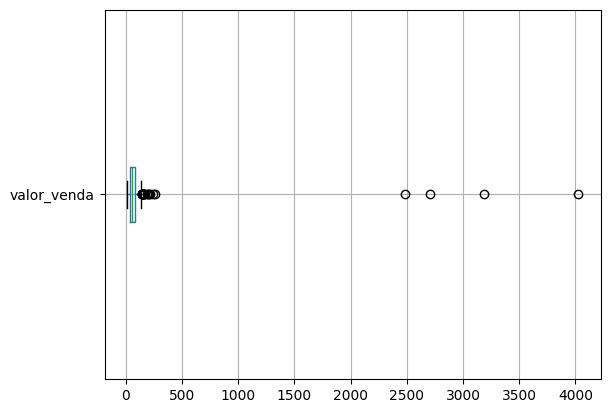

In [41]:
import matplotlib.pyplot as plt

df.boxplot(column='valor_venda', vert=False)
plt.show()

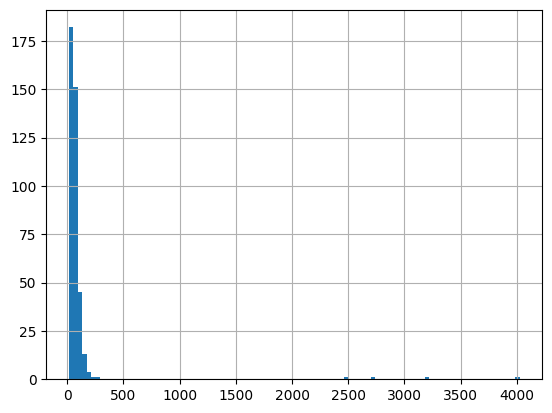

In [42]:
df['valor_venda'].hist(bins=100)
plt.show()

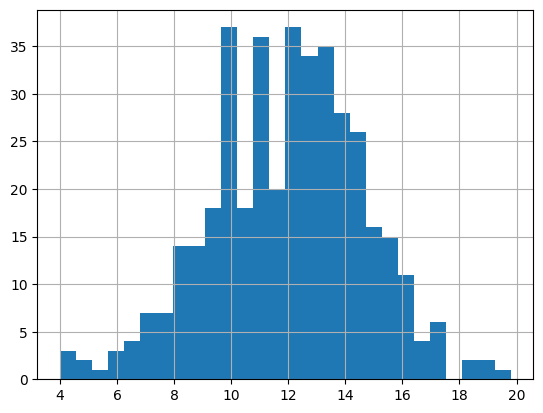

In [43]:
df['tempo_atendimento_min'].hist(bins=28)
plt.show()

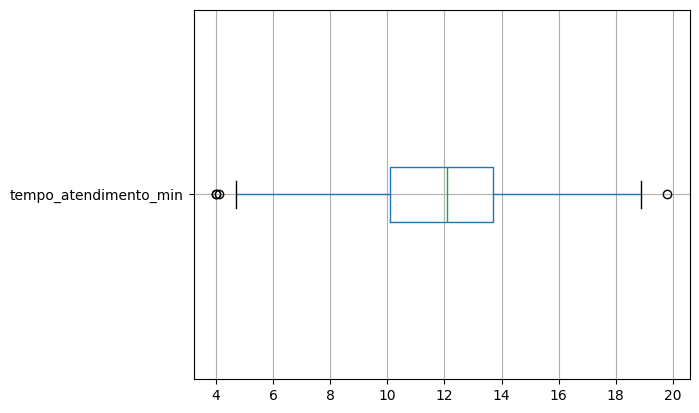

In [44]:
df.boxplot(column='tempo_atendimento_min', vert=False)
plt.show()

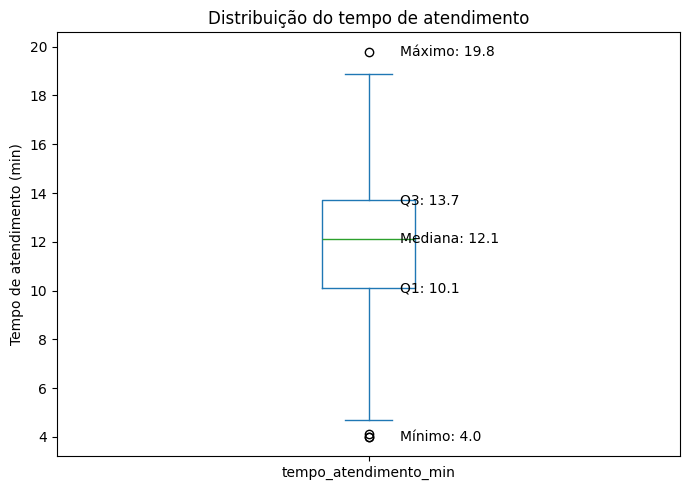

In [45]:
s = df['tempo_atendimento_min'].dropna()

q1 = s.quantile(0.25)
mediana = s.quantile(0.50)
q3 = s.quantile(0.75)
minimo = s.min()
maximo = s.max()

fig, ax = plt.subplots(figsize=(7, 5))

s.plot.box(ax=ax)

valores = {
    'Mínimo': minimo,
    'Q1': q1,
    'Mediana': mediana,
    'Q3': q3,
    'Máximo': maximo
}

for nome, valor in valores.items():
    ax.text(
        1.05, valor,
        f'{nome}: {valor:.1f}',
        va='center'
    )

ax.set_ylabel('Tempo de atendimento (min)')
ax.set_title('Distribuição do tempo de atendimento')
plt.tight_layout()
plt.show()

In [48]:
colunas = ['quantidade','valor_venda','desconto_pct','avaliacao_cliente','tempo_atendimento_min']
corr = df[colunas].corr().round(2)
display(corr)

,quantidade,valor_venda,desconto_pct,avaliacao_cliente,tempo_atendimento_min
quantidade,1.00,-0.03,0.02,0.05,-0.05
valor_venda,-0.03,1.00,0.03,-0.05,-0.01
desconto_pct,0.02,0.03,1.00,0.02,0.02
avaliacao_cliente,0.05,-0.05,0.02,1.00,0.02
tempo_atendimento_min,-0.05,-0.01,0.02,0.02,1.00
